# 04 · Machine learning: signal-like against background-like classifiers

**What this notebook does.** The $B^\pm\to K^\pm K^+K^-$ sample has no labels. We create *weak* labels from the
mass alone (events under the peak are signal-like, events far in the sidebands are background-like) and train
classifiers on the **other** variables (kaon momenta, particle identification, impact parameters, $B$ flight distance and
vertex quality) — never on the mass — so that the score can be used to select candidates without sculpting the
mass spectrum by construction. The notebook compares five classifiers, studies their regularisation, bias–variance
trade-off, calibration and uncertainty, and optimises their hyperparameters. The *use* of the selection for the
measurement of $A_{\rm raw}$ (stability, refits, Dalitz plane) is in notebook 05.

**Weak labels** (`ml_tools.weak_labels`), with $\mu,\sigma$ from the nominal Bayesian fit of notebook 01 of the Bayesian
analysis: signal-like $|m-\mu|<2\sigma$; background-like $m\in[5150,\mu-4\sigma]\cup[\mu+4\sigma,5600]$ MeV. The region
$5100$–$5150$ MeV (partially reconstructed $B$ decays, not representative of the background under the peak) and the
gaps $2$–$4\sigma$ are unlabeled. Class imbalance is handled with `balanced` class weights for **every** model.

**Models**: logistic regression (L2 and L1/Lasso), decision tree, random forest (RF), gradient boosting (GBM) and a
feed-forward neural network (FFNN). The reference model is the one with the best *cross-validated* AUC on the
training set (not on the test set).

### What goes into the report (appendix *Machine-learning analysis*)

| Section | Report | Figure |
|---|---|---|
| 1 | Weak labels and feature set | `ml_weak_labels` |
| 2 | Model comparison; regularization | `ml_nominal_roc`, `ml_regularization` |
| 3 | Model comparison (feature importance) | `ml_nominal_features` |
| 4 | Regularization, bias–variance, calibration | `ml_nominal_bias_variance`, `ml_nominal_calibration` |
| 5 | Uncertainty quantification | `ml_nominal_uncertainty` |
| 6 | Hyperparameter optimization | `ml_ffnn_search` |

### How to run
* Needs the result of notebook `01` of the Bayesian analysis (`../Bayesian/results/nominal/nominal_summary.json`).
* From scratch about 3 h on 10 cores (RF/GBM grid searches with repeated cross-validation, 168-configuration FFNN
  search, 10-seed deep ensemble). Each long block saves its result in `results/nominal/` and **resumes** from it;
  with the saved results the notebook takes about 5 min. Seeds are fixed and TensorFlow op determinism is enabled.

## 0 · Setup

In [1]:
import os, sys, json, time
import warnings
# sklearn >= 1.8 deprecates `penalty` in favour of `l1_ratio`; same models, the warnings only flood the output
warnings.filterwarnings("ignore", message=".*penalty.*")
warnings.filterwarnings("ignore", message=".*l1_ratio.*")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

os.environ.setdefault("TF_DETERMINISTIC_OPS", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # silence TensorFlow C++ info/warnings
import tensorflow as tf
from tensorflow import keras
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

from sklearn.model_selection import StratifiedKFold, cross_val_score, RepeatedStratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, accuracy_score
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.utils.class_weight import compute_sample_weight
from scipy.stats import ks_2samp, spearmanr

sys.path.insert(0, ".")        # ml_tools.py
sys.path.insert(0, "..")       # plot_style.py
import ml_tools as mn
import plot_style as ps
ps.use(); C = ps.COLORS

DATA_DIR    = "../../../opendata-project/Data"
RESULTS_DIR = os.path.join(os.getcwd(), "results", "nominal")
FIG_DIR     = os.path.join(os.getcwd(), "figures")
for d in (RESULTS_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)
P = lambda name: os.path.join(RESULTS_DIR, name)

# Settings of the long computations
CFG = dict(
    n_trees=300,          # trees of the reference random forest
    ffnn_epochs=100,      # maximum epochs of the FFNN (early stopping on the validation AUC)
    mc_passes=300,        # stochastic forward passes of MC dropout
    n_seeds=10,           # FFNN seeds of the deep ensemble
    n_boot=2000,          # bootstrap replicas of the test AUC
    rcv_repeats=10,       # repetitions of the 5-fold cross-validation of the RF/GBM grids
    rf_grid={"n_estimators": [200, 400, 600, 800, 1000, 1200], "max_depth": [6, 8, 10, 12, None], "min_samples_leaf": [5, 10, 20, 40]},
    gbm_grid={"n_estimators": [100, 200, 300, 400, 500], "max_depth": [1, 2, 3, 4, 5], "learning_rate": [0.01, 0.03, 0.05, 0.1]},
    ffnn_archs={"tiny_1layer": [8], "small_1layer": [16], "baseline_2layer": [32, 16], "wide_2layer": [64, 32],
                "deep_3layer": [64, 32, 16], "deep_4layer": [128, 64, 32, 16], "deep_5layer": [128, 64, 32, 16, 8]},
    ffnn_dropouts=[0.1, 0.2, 0.3, 0.4],
    ffnn_lrs=[0.0002, 0.0005, 0.001, 0.002, 0.003, 0.005],
    ffnn_search_folds=(5, 2), ffnn_search_epochs=60,
)

def save_json(name, obj):
    with open(P(name), "w") as f:
        json.dump(obj, f, indent=1)
    print("[saved]", os.path.relpath(P(name)))

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name)); plt.show(); print("[saved]", os.path.join("figures", name))

bayes = mn.load_bayes_summary()
MU, SIGMA = bayes["nominal"]["mu"]["median"], bayes["nominal"]["sigma"]["median"]
print(f"nominal Bayesian fit: mu = {MU:.2f} MeV, sigma = {SIGMA:.2f} MeV, A_raw = {bayes['nominal']['A']['median']:.4f}")

nominal Bayesian fit: mu = 5284.39 MeV, sigma = 18.00 MeV, A_raw = -0.0443


## 1 · Data, weak labels and features

`mn.load_data` applies the same preselection as the other analyses and computes the features: for each of the three
tracks the momentum components $p_x,p_y,p_z$, `ProbK`, `ProbPi` and the impact-parameter $\chi^2$ (18 features), plus
the $B$ flight distance and vertex $\chi^2$ (20 in total). The split is stratified, 60 % training / 20 % validation /
20 % test, with the standardisation fitted on the training set only.

Before training we check that the features carry information independent of the mass: the Kolmogorov–Smirnov test
between signal-like and background-like for the two $B$ variables, their maximal Spearman correlation with the track
features, and the number of principal components that explain 90 % of the variance.

In [2]:
data    = mn.load_data(DATA_DIR)
labeled = mn.weak_labels(data, MU, SIGMA)
n_sig, n_bkg = int(labeled.y.sum()), int((labeled.y == 0).sum())
print(f"candidates in [{mn.LO:.0f},{mn.HI:.0f}]: {len(data)}")
print(f"signal-like: |m-mu|<2sigma = [{MU-2*SIGMA:.1f},{MU+2*SIGMA:.1f}]: {n_sig}")
print(f"background-like: [{mn.SB_LO:.0f},{MU-4*SIGMA:.1f}] U [{MU+4*SIGMA:.1f},{mn.HI:.0f}]: {n_bkg}  (ratio {n_bkg/n_sig:.3f})")

sp = mn.make_split(labeled)
X_all, y_all = sp["X_all"], sp["y_all"]
X_train, X_val, X_test = sp["X_train"], sp["X_val"], sp["X_test"]
y_train, y_val, y_test = sp["y_train"], sp["y_val"], sp["y_test"]
X_train_s, X_val_s, X_test_s = sp["X_train_s"], sp["X_val_s"], sp["X_test_s"]
scaler, W, sw_train = sp["scaler"], sp["W"], sp["sw_train"]
print(f"train/val/test: {len(y_train)}/{len(y_val)}/{len(y_test)};  test background: {(y_test==0).sum()}")
print("class weights (balanced):", {k: round(v, 3) for k, v in W.items()})

expl = {}
for f in ["B_FlightDistance", "B_VertexChi2"]:
    ks = ks_2samp(labeled[f][labeled.y == 1], labeled[f][labeled.y == 0])
    rho = max(abs(spearmanr(labeled[f], labeled[g]).correlation) for g in mn.FEATURES[:18])
    expl[f] = {"ks_p": float(ks.pvalue), "max_abs_spearman_vs_track_features": float(rho)}
pca = PCA().fit(StandardScaler().fit_transform(X_all))
expl["pca_n_components_90pct"] = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.90) + 1)
print(expl)
save_json("data_labels.json", {"mu": MU, "sigma": SIGMA, "n_window": len(data), "n_signal_like": n_sig,
    "n_background_like": n_bkg, "n_train": len(y_train), "n_val": len(y_val), "n_test": len(y_test),
    "n_test_background": int((y_test == 0).sum()), "class_weights": W, "exploration": expl})

candidates in [5100,5600]: 19731
signal-like: |m-mu|<2sigma = [5248.4,5320.4]: 15130
background-like: [5150,5212.4] U [5356.4,5600]: 1940  (ratio 0.128)
train/val/test: 10242/3414/3414;  test background: 388
class weights (balanced): {0: 4.399, 1: 0.564}
{'B_FlightDistance': {'ks_p': 8.274393696315928e-144, 'max_abs_spearman_vs_track_features': 0.5251895774772006}, 'B_VertexChi2': {'ks_p': 2.294552235101204e-67, 'max_abs_spearman_vs_track_features': 0.04819978488058673}, 'pca_n_components_90pct': 15}
[saved] results/nominal/data_labels.json


**Figure `ml_weak_labels`.** Mass spectrum of the nominal window with the signal-like and background-like regions
(log scale); hatched: $5100$–$5150$ MeV, excluded from the labels; grey: unlabeled gaps.

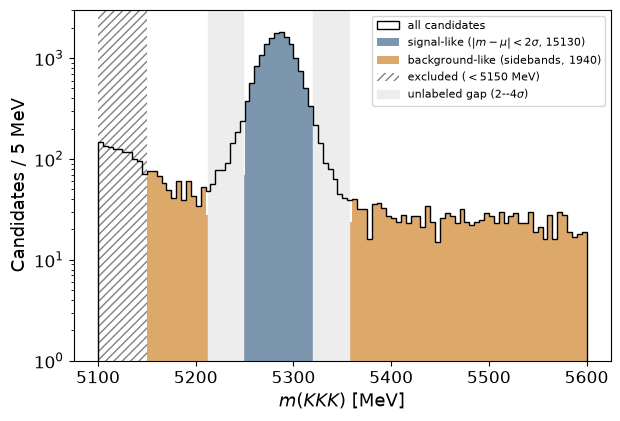

[saved] figures/ml_weak_labels.pdf


In [3]:
m = data.B_M.to_numpy()
sig = np.abs(m - MU) < 2 * SIGMA
bkg = ((m >= 5150) & (m < MU - 4 * SIGMA)) | ((m > MU + 4 * SIGMA) & (m <= 5600))
fig, ax = plt.subplots(figsize=(ps.SINGLE, 4.4))
bins = np.arange(5100, 5600.1, 5)
ax.hist(m, bins=bins, histtype="step", color="k", lw=1.0, label="all candidates")
ax.hist(m[sig], bins=bins, color=C["sig_like"], alpha=0.8, label="signal-like ($|m-\\mu|<2\\sigma$, %d)" % sig.sum())
ax.hist(m[bkg], bins=bins, color=C["bkg_like"], alpha=0.9, label="background-like (sidebands, %d)" % bkg.sum())
ax.axvspan(5100, 5150, facecolor="none", hatch="////", edgecolor="0.5", lw=0, label=r"excluded ($<5150$ MeV)")
ax.axvspan(MU - 4 * SIGMA, MU - 2 * SIGMA, color="0.93"); ax.axvspan(MU + 2 * SIGMA, MU + 4 * SIGMA, color="0.93", label=r"unlabeled gap ($2$--$4\sigma$)")
ax.set_yscale("log"); ax.set_ylim(1, 3e3)
ax.set_xlabel(r"$m(KKK)$ [MeV]"); ax.set_ylabel("Candidates / 5 MeV"); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
save_fig(fig, "ml_weak_labels.pdf")

## 2 · Models: cross-validated AUC, test AUC, regularisation

Five classifiers on the same training set. The ranking metric is the area under the ROC curve (AUC); the reference
model is chosen on the 5-fold cross-validated AUC of the training set. The test AUC is quoted with a bootstrap
uncertainty (2000 resamplings of the test set); the Brier score measures the calibration of the probabilities.

The logistic regression is also fitted with an $L_1$ (Lasso) and an $L_2$ (Ridge) penalty: the strength
$C=1/\alpha$ is scanned on a logarithmic grid and chosen on the cross-validated AUC.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=CFG["n_trees"], max_depth=8, min_samples_leaf=20,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42),
}
scaled = {"Logistic Regression"}          # models that take the standardised features
cv_auc, fitted = {}, {}
for name, mdl in models.items():
    Xtr = X_train_s if name in scaled else X_train
    params = {"sample_weight": sw_train} if name == "Gradient Boosting" else {}
    sc = cross_val_score(mdl, Xtr, y_train, cv=cv, scoring="roc_auc", params=params)
    cv_auc[name] = [float(sc.mean()), float(sc.std())]
    fitted[name] = mdl.fit(Xtr, y_train, **params)
    print(f"{name:20s} CV AUC = {sc.mean():.4f} +- {sc.std():.4f}")

# L1 / L2 regularisation sweep of the logistic regression
C_grid = np.logspace(-3, 2, 30)
auc_l1 = [cross_val_score(LogisticRegression(penalty="l1", solver="liblinear", C=c, class_weight="balanced", max_iter=2000,
          random_state=42), X_train_s, y_train, cv=cv, scoring="roc_auc").mean() for c in C_grid]
auc_l2 = [cross_val_score(LogisticRegression(penalty="l2", C=c, class_weight="balanced", max_iter=2000,
          random_state=42), X_train_s, y_train, cv=cv, scoring="roc_auc").mean() for c in C_grid]
C_l1, C_l2 = float(C_grid[int(np.argmax(auc_l1))]), float(C_grid[int(np.argmax(auc_l2))])
lasso = LogisticRegression(penalty="l1", solver="liblinear", C=C_l1, class_weight="balanced", max_iter=2000,
                           random_state=42).fit(X_train_s, y_train)
fitted["Logistic Regression (L1)"] = lasso; scaled.add("Logistic Regression (L1)")
regularization = {"C_best_l1": C_l1, "auc_best_l1": float(max(auc_l1)), "C_best_l2": C_l2, "auc_best_l2": float(max(auc_l2)),
                  "n_zero_coef_l1": int(np.sum(lasso.coef_ == 0)), "C_grid": C_grid.tolist(), "auc_l1": list(map(float, auc_l1)),
                  "auc_l2": list(map(float, auc_l2))}
print(f"L1: C={C_l1:.3g} AUC={max(auc_l1):.4f}, {regularization['n_zero_coef_l1']} coefficients set to zero;  "
      f"L2: C={C_l2:.3g} AUC={max(auc_l2):.4f}")

Logistic Regression  CV AUC = 0.7686 +- 0.0160


Decision Tree        CV AUC = 0.8164 +- 0.0110


Random Forest        CV AUC = 0.8631 +- 0.0170


Gradient Boosting    CV AUC = 0.8659 +- 0.0163


L1: C=0.117 AUC=0.7686, 0 coefficients set to zero;  L2: C=9.24 AUC=0.7686


**FFNN.** Fully connected network, ReLU activations, dropout, sigmoid output, binary cross-entropy, Adam; early
stopping on the validation AUC; `balanced` class weights; fixed seed and TensorFlow op determinism, so that the
training is reproducible.

In [5]:
def build_ffnn(layers=(32, 16), dropout=0.2, lr=1e-3, seed=0):
    keras.utils.set_random_seed(seed)
    net = [keras.layers.Input(shape=(X_train_s.shape[1],))]
    for u in layers:
        net += [keras.layers.Dense(u, activation="relu"), keras.layers.Dropout(dropout)]
    net += [keras.layers.Dense(1, activation="sigmoid")]
    m = keras.Sequential(net)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    return m

def train_ffnn(seed=0, layers=(32, 16), dropout=0.2, lr=1e-3, Xtr=None, ytr=None, Xva=None, yva=None, epochs=None, patience=8):
    Xtr = X_train_s if Xtr is None else Xtr; ytr = y_train if ytr is None else ytr
    Xva = X_val_s if Xva is None else Xva; yva = y_val if yva is None else yva
    m = build_ffnn(layers, dropout, lr, seed)
    es = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=patience, restore_best_weights=True)
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs or CFG["ffnn_epochs"], batch_size=256,
              class_weight=mn.balanced_weights(ytr), callbacks=[es], verbose=0)
    return m, h

ffnn, ffnn_hist = train_ffnn(seed=0)
fitted["FFNN"] = ffnn; scaled.add("FFNN")
print(f"FFNN (seed 0): {len(ffnn_hist.history['loss'])} epochs, val AUC {max(ffnn_hist.history['val_auc']):.4f}")

def score(name, X_raw, X_s):
    mdl = fitted[name]
    if name == "FFNN":
        return mdl.predict(X_s, verbose=0).ravel()
    return mdl.predict_proba(X_s if name in scaled else X_raw)[:, 1]

order = ["Logistic Regression", "Logistic Regression (L1)", "Decision Tree", "Random Forest", "Gradient Boosting", "FFNN"]
scores_test  = {n: score(n, X_test, X_test_s) for n in order}
test_auc     = {n: float(roc_auc_score(y_test, s)) for n, s in scores_test.items()}
test_auc_sd  = {n: mn.bootstrap_auc_sd(y_test, s, n=CFG["n_boot"]) for n, s in scores_test.items()}
brier        = {n: float(brier_score_loss(y_test, s)) for n, s in scores_test.items()}
REF = max(cv_auc, key=lambda n: cv_auc[n][0])          # reference model: best CV AUC, not best test AUC
for n in order:
    print(f"{n:26s} test AUC = {test_auc[n]:.4f} +- {test_auc_sd[n]:.4f}   Brier = {brier[n]:.4f}")
print("reference model (best CV AUC):", REF)
np.save(P("test_scores.npy"), np.column_stack([y_test] + [scores_test[n] for n in order]))
save_json("models.json", {"cv_auc": cv_auc, "test_auc": test_auc, "test_auc_bootstrap_sd": test_auc_sd, "brier": brier,
    "reference_model": REF, "order": order, "regularization": regularization,
    "ffnn_seed0": {"epochs": len(ffnn_hist.history["loss"]), "val_auc": float(max(ffnn_hist.history["val_auc"]))}})

FFNN (seed 0): 56 epochs, val AUC 0.8679


Logistic Regression        test AUC = 0.7713 +- 0.0131   Brier = 0.1967
Logistic Regression (L1)   test AUC = 0.7707 +- 0.0131   Brier = 0.1976
Decision Tree              test AUC = 0.8243 +- 0.0125   Brier = 0.1334
Random Forest              test AUC = 0.8604 +- 0.0120   Brier = 0.1222
Gradient Boosting          test AUC = 0.8643 +- 0.0116   Brier = 0.1156
FFNN                       test AUC = 0.8568 +- 0.0117   Brier = 0.1345
reference model (best CV AUC): Gradient Boosting
[saved] results/nominal/models.json


**Figure `ml_nominal_roc`.** ROC curves on the test set (test AUC in the legend); the open circle is the working
point of the reference model at score $>0.5$, the cut used in notebook 05.

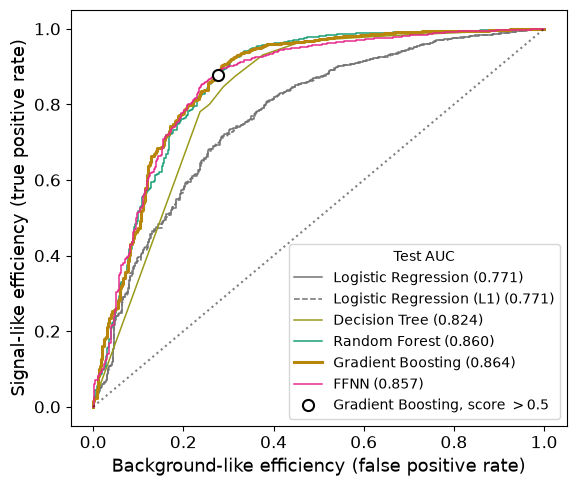

[saved] figures/ml_nominal_roc.pdf


In [6]:
y = y_test
scores = np.column_stack([y_test] + [scores_test[n] for n in order])
styles = {n_: (ps.MODELS[n_], "--" if n_.endswith("(L1)") else "-") for n_ in ps.MODELS}
fig, ax = plt.subplots(figsize=(ps.SINGLE, 5.4))
for k, name in enumerate(order, 1):
    fpr, tpr, _ = roc_curve(y, scores[:, k]); col, ls_ = styles[name]
    ax.plot(fpr, tpr, color=col, ls=ls_, lw=2.2 if name == REF else 1.1, label=f"{name} ({roc_auc_score(y, scores[:, k]):.3f})")
k_ref = order.index(REF) + 1
sel_ = scores[:, k_ref] > 0.5
ax.plot([np.mean(sel_[y == 0])], [np.mean(sel_[y == 1])], "o", ms=8, mfc="white", mec="k", mew=1.5, label=f"{REF}, score $>0.5$")
ax.plot([0, 1], [0, 1], "k:", alpha=0.5)
ax.set_xlabel("Background-like efficiency (false positive rate)"); ax.set_ylabel("Signal-like efficiency (true positive rate)")
ax.legend(loc="lower right", fontsize=10, title="Test AUC", title_fontsize=10)
save_fig(fig, "ml_nominal_roc.pdf")

**Figure `ml_regularization`.** Cross-validated AUC against the regularisation strength $C=1/\alpha$ for the $L_1$
and $L_2$ penalties; dotted: best value. The AUC is flat over a wide range: the logistic regression is not limited
by the variance but by the linear form of the decision boundary.

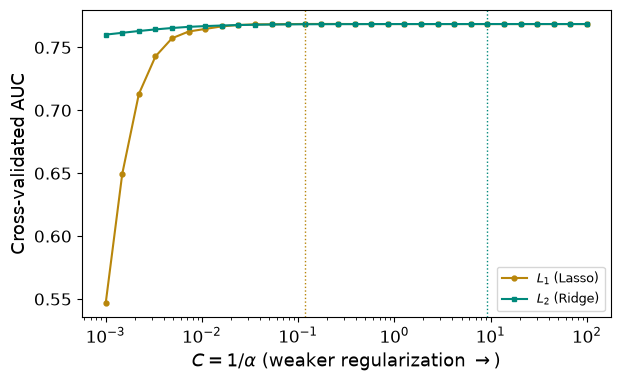

[saved] figures/ml_regularization.pdf


In [7]:
Cg = np.array(regularization["C_grid"])
fig, ax = plt.subplots(figsize=(ps.SINGLE, 4.0))
ax.plot(Cg, regularization["auc_l1"], "o-", ms=3.5, color=C["ml"], label=r"$L_1$ (Lasso)")
ax.plot(Cg, regularization["auc_l2"], "s-", ms=3.5, color=C["freq"], label=r"$L_2$ (Ridge)")
ax.axvline(regularization["C_best_l1"], color=C["ml"], ls=":", lw=1); ax.axvline(regularization["C_best_l2"], color=C["freq"], ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel(r"$C=1/\alpha$ (weaker regularization $\to$)"); ax.set_ylabel("Cross-validated AUC")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
save_fig(fig, "ml_regularization.pdf")

## 3 · Which features matter

Two measures of the relevance of a feature: the Gini importance of the random forest and the magnitude of the
$L_1$-regularised logistic-regression coefficient on standardised features. Their rank correlation (Spearman) tells
whether a nonlinear and a linear model agree; the $B$-candidate variables (flight distance, vertex $\chi^2$) are
highlighted.

**Figure `ml_nominal_features`.** (a) random-forest importance, (b) $|$Lasso coefficient$|$, same feature order.

Spearman(RF importance, |Lasso coef|) = 0.42 (p=6.3e-02)
  B_FlightDistance   RF rank  4   Lasso rank  1
  B_VertexChi2       RF rank  5   Lasso rank  4
  H1_IPChi2          RF rank  2   Lasso rank 11
  H2_IPChi2          RF rank  1   Lasso rank  7
  H3_IPChi2          RF rank  3   Lasso rank  2
[saved] results/nominal/features.json


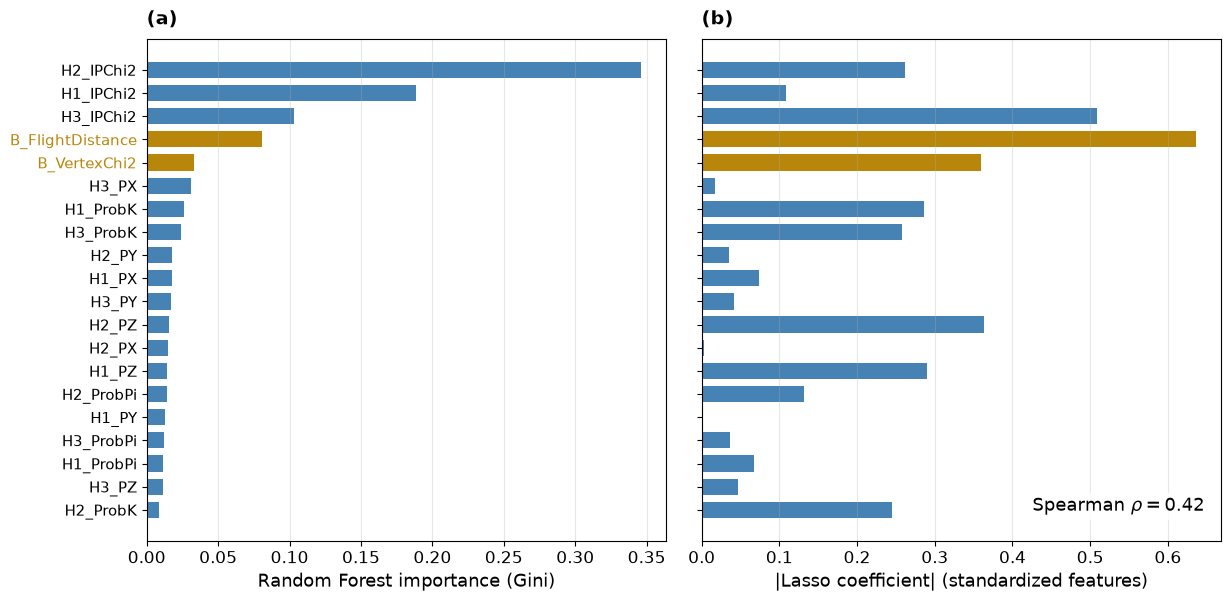

[saved] figures/ml_nominal_features.pdf


In [8]:
imp  = fitted["Random Forest"].feature_importances_
coef = np.abs(lasso.coef_.ravel())
rank_imp  = {f: int(r) for f, r in zip(mn.FEATURES, (-imp).argsort().argsort() + 1)}
rank_coef = {f: int(r) for f, r in zip(mn.FEATURES, (-coef).argsort().argsort() + 1)}
rho_ic = spearmanr(imp, coef)
feat = {"importance": dict(zip(mn.FEATURES, map(float, imp))), "abs_lasso_coef": dict(zip(mn.FEATURES, map(float, coef))),
        "rank_importance": rank_imp, "rank_lasso": rank_coef, "spearman_importance_vs_lasso": float(rho_ic.correlation),
        "spearman_p": float(rho_ic.pvalue)}
print(f"Spearman(RF importance, |Lasso coef|) = {rho_ic.correlation:.2f} (p={rho_ic.pvalue:.1e})")
for f in ["B_FlightDistance", "B_VertexChi2", "H1_IPChi2", "H2_IPChi2", "H3_IPChi2"]:
    print(f"  {f:18s} RF rank {rank_imp[f]:2d}   Lasso rank {rank_coef[f]:2d}")
save_json("features.json", feat)

names_f = list(feat["importance"].keys())
imp_a = np.array([feat["importance"][n] for n in names_f]); coef_a = np.array([feat["abs_lasso_coef"][n] for n in names_f])
order_f = np.argsort(imp_a)                          # ascending: most important at the top of a barh
fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 6.2), sharey=True)
yy = np.arange(len(names_f))
is_b = np.array([names_f[i].startswith("B_") for i in order_f])
for a, val, lab in ((axs[0], imp_a, "Random Forest importance (Gini)"), (axs[1], coef_a, "|Lasso coefficient| (standardized features)")):
    a.barh(yy, val[order_f], color=np.where(is_b, C["ml"], C["signal"]), height=0.7)
    a.set_xlabel(lab); a.grid(axis="x", alpha=0.3)
axs[0].set_yticks(yy); axs[0].set_yticklabels([names_f[i] for i in order_f], fontsize=11)
for t_, b_ in zip(axs[0].get_yticklabels(), is_b):
    if b_: t_.set_color(C["ml"])
ps.letter(axs[0], "a"); ps.letter(axs[1], "b")
ps.panel_label(axs[1], f"Spearman $\\rho = {feat['spearman_importance_vs_lasso']:.2f}$", loc="lower right")
plt.tight_layout()
save_fig(fig, "ml_nominal_features.pdf")

## 4 · Bias–variance trade-off and calibration

**Bias–variance.** The gradient-boosting model is evaluated after each boosting stage (`staged_predict_proba`) on the
training and on the test set. A growing gap between the two curves is variance (overfitting); a common plateau at a
low value is bias. The dotted line is the accuracy of the trivial classifier that always answers *signal-like*.

**Calibration.** A score is a probability only if, among the candidates with score $\approx p$, a fraction $p$ is
signal-like. The reliability curve of the random forest is compared with its isotonic-regression recalibration
(`CalibratedClassifierCV`, 5-fold) through the Brier score $\langle(s-y)^2\rangle$.

**Figures `ml_nominal_bias_variance`, `ml_nominal_calibration`.**

{'auc_gap_20': 0.0177, 'auc_gap_final': 0.0839, 'acc_gap_20': 0.0129, 'acc_gap_final': 0.0289, 'accuracy_always_signal': 0.8864}


RF Brier: raw 0.1222 -> isotonic 0.0619
[saved] results/nominal/bias_variance_calibration.json


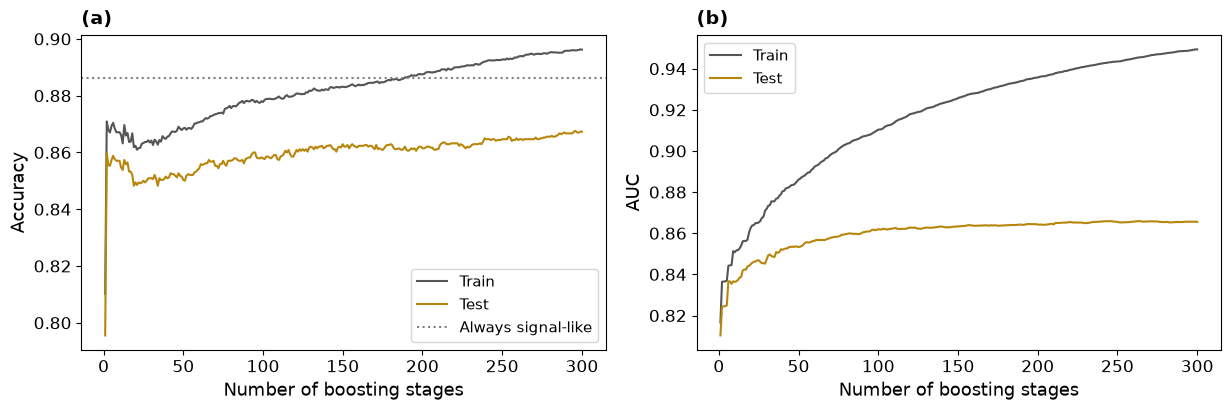

[saved] figures/ml_nominal_bias_variance.pdf


In [9]:
gbm_bv = GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
gbm_bv.fit(X_train, y_train, sample_weight=sw_train)
acc_tr, acc_te, auc_tr, auc_te = [], [], [], []
for ptr, pte in zip(gbm_bv.staged_predict_proba(X_train), gbm_bv.staged_predict_proba(X_test)):
    acc_tr.append(accuracy_score(y_train, ptr[:, 1] > 0.5)); acc_te.append(accuracy_score(y_test, pte[:, 1] > 0.5))
    auc_tr.append(roc_auc_score(y_train, ptr[:, 1]));        auc_te.append(roc_auc_score(y_test, pte[:, 1]))
bias_variance = {"accuracy_train": acc_tr, "accuracy_test": acc_te, "auc_train": auc_tr, "auc_test": auc_te,
                 "auc_gap_20": float(auc_tr[19] - auc_te[19]), "auc_gap_final": float(auc_tr[-1] - auc_te[-1]),
                 "acc_gap_20": float(acc_tr[19] - acc_te[19]), "acc_gap_final": float(acc_tr[-1] - acc_te[-1]),
                 "accuracy_always_signal": float(y_test.mean())}
print({k: round(v, 4) for k, v in bias_variance.items() if not isinstance(v, list)})

base = RandomForestClassifier(n_estimators=CFG["n_trees"], max_depth=8, min_samples_leaf=20, class_weight="balanced",
                              random_state=42, n_jobs=-1)
cal_model = CalibratedClassifierCV(base, method="isotonic", cv=5).fit(X_train, y_train)
s_cal = cal_model.predict_proba(X_test)[:, 1]
pt_r, pp_r = calibration_curve(y_test, scores_test["Random Forest"], n_bins=10)
pt_c, pp_c = calibration_curve(y_test, s_cal, n_bins=10)
calibration = {"brier_raw_rf": brier["Random Forest"], "brier_isotonic_rf": float(brier_score_loss(y_test, s_cal)),
               "raw": {"pred": pp_r.tolist(), "obs": pt_r.tolist()}, "isotonic": {"pred": pp_c.tolist(), "obs": pt_c.tolist()}}
print(f"RF Brier: raw {calibration['brier_raw_rf']:.4f} -> isotonic {calibration['brier_isotonic_rf']:.4f}")
save_json("bias_variance_calibration.json", {"bias_variance": bias_variance, "calibration": calibration})

bv = bias_variance
fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 4.3))
n_st = np.arange(1, len(bv["accuracy_train"]) + 1)
axs[0].plot(n_st, bv["accuracy_train"], color=C["count"], label="Train"); axs[0].plot(n_st, bv["accuracy_test"], color=C["ml"], label="Test")
axs[0].axhline(bv["accuracy_always_signal"], color="gray", ls=":", label="Always signal-like")
axs[0].set_ylabel("Accuracy")
axs[1].plot(n_st, bv["auc_train"], color=C["count"], label="Train"); axs[1].plot(n_st, bv["auc_test"], color=C["ml"], label="Test")
axs[1].set_ylabel("AUC")
for k_, a in enumerate(axs):
    a.set_xlabel("Number of boosting stages"); a.legend(); ps.letter(a, "ab"[k_])
plt.tight_layout()
save_fig(fig, "ml_nominal_bias_variance.pdf")

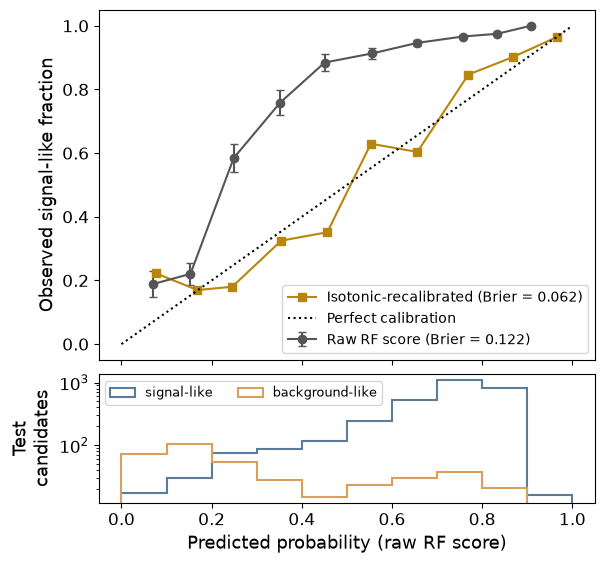

[saved] figures/ml_nominal_calibration.pdf


In [10]:
rf_s = scores_test["Random Forest"]
edges10 = np.linspace(0, 1, 11)
cnt, _ = np.histogram(rf_s, edges10); cnt = cnt[cnt > 0]                 # calibration_curve drops empty bins
obs_r = np.array(calibration["raw"]["obs"]); err_r = np.sqrt(obs_r * (1 - obs_r) / cnt)
fig, (ax, axh) = plt.subplots(2, 1, figsize=(ps.SINGLE, 6.4), sharex=True, gridspec_kw={"height_ratios": [3, 1.1], "hspace": 0.06})
ax.errorbar(calibration["raw"]["pred"], obs_r, yerr=err_r, fmt="o-", capsize=3, color=C["count"],
            label=f"Raw RF score (Brier = {calibration['brier_raw_rf']:.3f})")
ax.plot(calibration["isotonic"]["pred"], calibration["isotonic"]["obs"], "s-", color=C["ml"],
        label=f"Isotonic-recalibrated (Brier = {calibration['brier_isotonic_rf']:.3f})")
ax.plot([0, 1], [0, 1], "k:", label="Perfect calibration")
ax.set_ylabel("Observed signal-like fraction"); ax.legend(loc="lower right", fontsize=10)
for lab_, msk, col in (("signal-like", y_test == 1, C["sig_like"]), ("background-like", y_test == 0, C["bkg_like"])):
    axh.hist(rf_s[msk], bins=edges10, histtype="step", lw=1.5, color=col, label=lab_)
axh.set_yscale("log"); axh.set_xlabel("Predicted probability (raw RF score)"); axh.set_ylabel("Test\ncandidates")
axh.legend(loc="upper left", fontsize=9, ncol=2)
save_fig(fig, "ml_nominal_calibration.pdf")

## 5 · Uncertainty of the score

Three estimators of the per-candidate uncertainty of the classifier output, on the test set:

* **random forest:** standard deviation of the prediction across the 300 trees (spread of the ensemble);
* **MC dropout:** the FFNN with dropout kept active, 300 stochastic forward passes;
* **deep ensemble:** 10 FFNNs trained from different seeds.

Their agreement is quantified by the Spearman rank correlation. The dependence of the random-forest spread on the
size of the training set (25 %, 50 %, 100 %) separates the *epistemic* part, which shrinks with more data, from the
irreducible overlap of the two classes.

**Figure `ml_nominal_uncertainty`.** (a) spread against the mean score, by class (band: 16th–84th percentile);
(b) distribution of the three estimators; (c) dependence on the training-set size.

In [11]:
rf = fitted["Random Forest"]
per_tree = np.stack([t.predict_proba(X_test)[:, 1] for t in rf.estimators_])
rf_std, rf_mean = per_tree.std(axis=0), per_tree.mean(axis=0)
mc = np.stack([ffnn(X_test_s, training=True).numpy().ravel() for _ in range(CFG["mc_passes"])])
mc_std = mc.std(axis=0)

def _ens():
    rows, preds = [], []
    for s in range(CFG["n_seeds"]):
        m_s, h_s = train_ffnn(seed=s)
        p_s = m_s.predict(X_test_s, verbose=0).ravel()
        mc_s = np.stack([m_s(X_test_s, training=True).numpy().ravel() for _ in range(CFG["mc_passes"])]).std(axis=0)
        rows.append({"seed": s, "test_auc": float(roc_auc_score(y_test, p_s)), "brier": float(brier_score_loss(y_test, p_s)),
                     "mc_mean": float(mc_s.mean()), "mc_bkg": float(mc_s[y_test == 0].mean()), "mc_sig": float(mc_s[y_test == 1].mean()),
                     "spearman_mc_rf": float(spearmanr(mc_s, rf_std).correlation)})
        preds.append(p_s.tolist())
        print(f"  seed {s}: AUC {rows[-1]['test_auc']:.4f}  MC {rows[-1]['mc_mean']:.4f}")
    return {"rows": rows, "preds": preds}
ens = mn.json_cached(P("deep_ensemble.json"), _ens, key={"n_seeds": CFG["n_seeds"], "epochs": CFG["ffnn_epochs"], "mc": CFG["mc_passes"]})
ens_preds = np.array(ens["preds"]); de_std = ens_preds.std(axis=0)
auc_seeds = np.array([r["test_auc"] for r in ens["rows"]])

def _size():
    out = []
    for frac in (0.25, 0.5, 1.0):
        idx = np.random.default_rng(7).permutation(len(y_train))[: int(frac * len(y_train))]
        mm = RandomForestClassifier(n_estimators=CFG["n_trees"], max_depth=8, min_samples_leaf=20, class_weight="balanced",
                                    random_state=42, n_jobs=-1).fit(X_train[idx], y_train[idx])
        st = np.stack([t.predict_proba(X_test)[:, 1] for t in mm.estimators_]).std(axis=0)
        out.append({"fraction": frac, "n_train": int(len(idx)), "rf_std_mean": float(st.mean()),
                    "rf_std_bkg": float(st[y_test == 0].mean()), "rf_std_sig": float(st[y_test == 1].mean()),
                    "test_auc": float(roc_auc_score(y_test, mm.predict_proba(X_test)[:, 1]))})
        print(f"  training {frac:.0%}: mean RF spread {out[-1]['rf_std_mean']:.4f}, AUC {out[-1]['test_auc']:.4f}")
    return {"rows": out}
size_study = mn.json_cached(P("training_size_study.json"), _size, key={"n_trees": CFG["n_trees"]})

uncertainty = {
    "rf_std_mean": float(rf_std.mean()), "rf_std_bkg": float(rf_std[y_test == 0].mean()), "rf_std_sig": float(rf_std[y_test == 1].mean()),
    "mc_dropout_seed0": {"mean": float(mc_std.mean()), "bkg": float(mc_std[y_test == 0].mean()), "sig": float(mc_std[y_test == 1].mean())},
    "deep_ensemble_std": {"mean": float(de_std.mean()), "bkg": float(de_std[y_test == 0].mean()), "sig": float(de_std[y_test == 1].mean())},
    "ffnn_seed_spread": {"auc_mean": float(auc_seeds.mean()), "auc_sd": float(auc_seeds.std(ddof=1)) if len(auc_seeds) > 1 else 0.0,
                         "mc_mean_over_seeds": float(np.mean([r["mc_mean"] for r in ens["rows"]])),
                         "mc_sd_over_seeds": float(np.std([r["mc_mean"] for r in ens["rows"]], ddof=1)) if len(auc_seeds) > 1 else 0.0},
    "spearman": {"mc_vs_rf": float(spearmanr(mc_std, rf_std).correlation), "deep_ens_vs_rf": float(spearmanr(de_std, rf_std).correlation),
                 "deep_ens_vs_mc": float(spearmanr(de_std, mc_std).correlation)},
    "training_size": size_study["rows"],
}
print(json.dumps({k: v for k, v in uncertainty.items() if k != "training_size"}, indent=1))
np.save(P("uncertainty_test.npy"), np.column_stack([y_test, rf_mean, rf_std, mc_std, de_std]))
save_json("uncertainty.json", uncertainty)

[resume] results/nominal/deep_ensemble.json
[resume] results/nominal/training_size_study.json
{
 "rf_std_mean": 0.1777698804558903,
 "rf_std_bkg": 0.18000329574872304,
 "rf_std_sig": 0.17748350731193158,
 "mc_dropout_seed0": {
  "mean": 0.09490814805030823,
  "bkg": 0.10269788652658463,
  "sig": 0.09390934556722641
 },
 "deep_ensemble_std": {
  "mean": 0.049892450464056756,
  "bkg": 0.04703217223687162,
  "sig": 0.05025920127441626
 },
 "ffnn_seed_spread": {
  "auc_mean": 0.8540368779852958,
  "auc_sd": 0.005321983348159775,
  "mc_mean_over_seeds": 0.09936581179499626,
  "mc_sd_over_seeds": 0.006447620226138854
 },
 "spearman": {
  "mc_vs_rf": 0.5690573035288482,
  "deep_ens_vs_rf": 0.4092966566661963,
  "deep_ens_vs_mc": 0.5384565538971905
 }
}
[saved] results/nominal/uncertainty.json


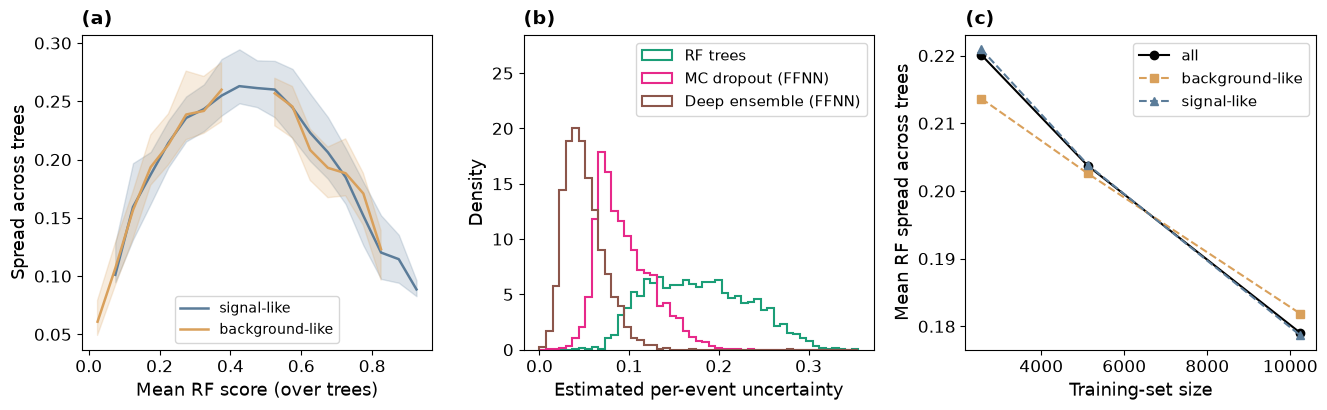

[saved] figures/ml_nominal_uncertainty.pdf


In [12]:
yt = y_test
fig, axs = plt.subplots(1, 3, figsize=(ps.TRIPLE, 4.3))
eb = np.linspace(0, 1, 21); cb_ = 0.5 * (eb[1:] + eb[:-1])
for lab_, msk, col in (("signal-like", yt == 1, C["sig_like"]), ("background-like", yt == 0, C["bkg_like"])):
    med, lo_, hi_ = [], [], []
    for x0, x1 in zip(eb[:-1], eb[1:]):
        v = rf_std[msk & (rf_mean >= x0) & (rf_mean < x1)]
        med.append(np.median(v) if len(v) >= 10 else np.nan)
        lo_.append(np.percentile(v, 16) if len(v) >= 10 else np.nan); hi_.append(np.percentile(v, 84) if len(v) >= 10 else np.nan)
    axs[0].plot(cb_, med, color=col, lw=1.8, label=lab_)
    axs[0].fill_between(cb_, lo_, hi_, color=col, alpha=0.2)
axs[0].set_xlabel("Mean RF score (over trees)"); axs[0].set_ylabel("Spread across trees"); axs[0].legend(loc="lower center", fontsize=10)
bins = np.linspace(0, max(rf_std.max(), mc_std.max(), de_std.max()), 50)
for arr, lab, col in ((rf_std, "RF trees", ps.ESTIMATORS["rf"]), (mc_std, "MC dropout (FFNN)", ps.ESTIMATORS["mc"]),
                      (de_std, "Deep ensemble (FFNN)", ps.ESTIMATORS["de"])):
    axs[1].hist(arr, bins=bins, histtype="step", density=True, lw=1.5, label=lab, color=col)
axs[1].set_xlabel("Estimated per-event uncertainty"); axs[1].set_ylabel("Density")
axs[1].set_ylim(0, axs[1].get_ylim()[1] * 1.35); axs[1].legend(loc="upper right")
ts = uncertainty["training_size"]
axs[2].plot([t["n_train"] for t in ts], [t["rf_std_mean"] for t in ts], "o-", color="k", label="all")
axs[2].plot([t["n_train"] for t in ts], [t["rf_std_bkg"] for t in ts], "s--", color=C["bkg_like"], label="background-like")
axs[2].plot([t["n_train"] for t in ts], [t["rf_std_sig"] for t in ts], "^--", color=C["sig_like"], label="signal-like")
axs[2].set_xlabel("Training-set size"); axs[2].set_ylabel("Mean RF spread across trees"); axs[2].legend()
for k_, a in enumerate(axs):
    ps.letter(a, "abc"[k_])
plt.tight_layout()
save_fig(fig, "ml_nominal_uncertainty.pdf")

## 6 · Hyperparameter optimisation

* **RF and GBM:** exhaustive grid (`GridSearchCV`) with 5-fold cross-validation repeated 10 times, scored on the AUC
  (120 and 100 configurations). The test AUC of the best model is compared with the default one used above.
* **FFNN:** 168 configurations (7 architectures $\times$ 4 dropout rates $\times$ 6 learning rates), 5-fold
  cross-validation repeated twice, 60 epochs with early stopping. Each configuration is appended to
  `ffnn_search.jsonl` (checkpoint).

The question is not only which configuration is best but whether the gain is larger than the seed-to-seed spread of
the FFNN (deep ensemble above): if not, the default is adequate.

**Figure `ml_ffnn_search`.** Cross-validated AUC of the 168 configurations, by architecture (black: best of each
architecture).

In [13]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=CFG["rcv_repeats"], random_state=42)
def _hp():
    out = {}
    for name, est, grid, params in (
        ("Random Forest", RandomForestClassifier(class_weight="balanced", random_state=42), CFG["rf_grid"], {}),
        ("Gradient Boosting", GradientBoostingClassifier(random_state=42), CFG["gbm_grid"], {"sample_weight": sw_train})):
        t0 = time.time()
        gs = GridSearchCV(est, grid, cv=rcv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train, **params)
        s = gs.best_estimator_.predict_proba(X_test)[:, 1]
        out[name] = {"best_params": gs.best_params_, "best_cv_auc": float(gs.best_score_),
                     "best_cv_auc_sd": float(gs.cv_results_["std_test_score"][gs.best_index_]),
                     "test_auc": float(roc_auc_score(y_test, s)), "test_auc_bootstrap_sd": mn.bootstrap_auc_sd(y_test, s, n=CFG["n_boot"]),
                     "default_test_auc": test_auc[name], "n_configs": int(len(gs.cv_results_["params"])), "minutes": round((time.time()-t0)/60, 1)}
        print(name, out[name])
    return out
hp = mn.json_cached(P("hyperparameter_search.json"), _hp, key={"rf": CFG["rf_grid"], "gbm": CFG["gbm_grid"], "rep": CFG["rcv_repeats"]})
for name, r in hp.items():
    if name != "_key":
        print(f"{name:18s} best CV AUC {r['best_cv_auc']:.4f} +- {r['best_cv_auc_sd']:.4f}  test AUC {r['test_auc']:.4f} (default {r['default_test_auc']:.4f})  {r['best_params']}")

[resume] results/nominal/hyperparameter_search.json
Random Forest      best CV AUC 0.8706 +- 0.0132  test AUC 0.8656 (default 0.8604)  {'max_depth': 12, 'min_samples_leaf': 5, 'n_estimators': 400}
Gradient Boosting  best CV AUC 0.8684 +- 0.0130  test AUC 0.8650 (default 0.8643)  {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300}


FFNN search: 168 already done, 0 to do


{
 "n_configs": 168,
 "best": {
  "arch": "deep_3layer",
  "layers": [
   64,
   32,
   16
  ],
  "dropout": 0.2,
  "lr": 0.003,
  "cv_auc_mean": 0.8585050463676452,
  "cv_auc_std": 0.01735789980978991,
  "seconds": 16.7
 },
 "best_test_auc": 0.8606271420881569,
 "default_test_auc": 0.856796935153072,
 "default_seed_spread_auc_sd": 0.005321983348159775
}
[saved] results/nominal/ffnn_search_summary.json


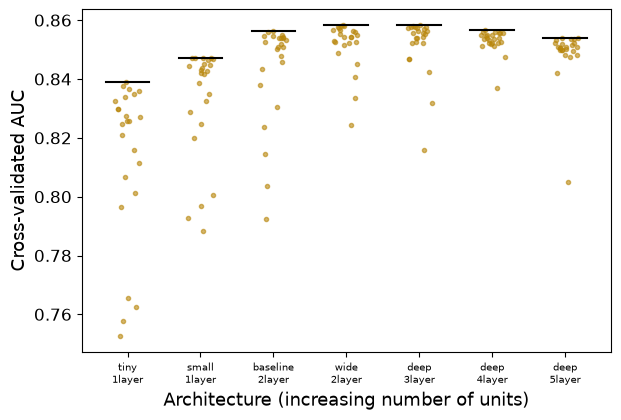

[saved] figures/ml_ffnn_search.pdf


In [14]:
f_ffnn = P("ffnn_search.jsonl")
done = {(r["arch"], r["dropout"], r["lr"]) for r in mn.jsonl_load(f_ffnn)}
fcv = RepeatedStratifiedKFold(n_splits=CFG["ffnn_search_folds"][0], n_repeats=CFG["ffnn_search_folds"][1], random_state=42)
configs = [(a, d, lr) for a in CFG["ffnn_archs"] for d in CFG["ffnn_dropouts"] for lr in CFG["ffnn_lrs"]]
print(f"FFNN search: {len(done)} already done, {len([c for c in configs if c not in done])} to do")
for k, (a, d, lr) in enumerate(configs, 1):
    if (a, d, lr) in done:
        continue
    t0, aucs = time.time(), []
    for f, (tr, va) in enumerate(fcv.split(X_train_s, y_train)):
        m_, h_ = train_ffnn(seed=f, layers=tuple(CFG["ffnn_archs"][a]), dropout=d, lr=lr, Xtr=X_train_s[tr], ytr=y_train[tr],
                            Xva=X_train_s[va], yva=y_train[va], epochs=CFG["ffnn_search_epochs"], patience=6)
        aucs.append(max(h_.history["val_auc"]))
    mn.jsonl_append(f_ffnn, {"arch": a, "layers": CFG["ffnn_archs"][a], "dropout": d, "lr": lr,
                             "cv_auc_mean": float(np.mean(aucs)), "cv_auc_std": float(np.std(aucs)), "seconds": round(time.time()-t0, 1)})
    if k % 10 == 0 or k == len(configs):
        print(f"  {k}/{len(configs)}")
search = sorted(mn.jsonl_load(f_ffnn), key=lambda r: -r["cv_auc_mean"])
best = search[0]
m_best, _ = train_ffnn(seed=0, layers=tuple(best["layers"]), dropout=best["dropout"], lr=best["lr"], patience=10)
s_best = m_best.predict(X_test_s, verbose=0).ravel()
ffnn_search = {"n_configs": len(search), "top5": search[:5], "best": best, "best_test_auc": float(roc_auc_score(y_test, s_best)),
               "default_test_auc": test_auc["FFNN"], "default_seed_spread_auc_sd": uncertainty["ffnn_seed_spread"]["auc_sd"]}
print(json.dumps({k: v for k, v in ffnn_search.items() if k != "top5"}, indent=1))
save_json("ffnn_search_summary.json", ffnn_search)

rows = search
archs = []
for r in mn.jsonl_load(f_ffnn):
    if r["arch"] not in archs: archs.append(r["arch"])
size = {a: sum(next(rr["layers"] for rr in rows if rr["arch"] == a)) for a in archs}
archs.sort(key=lambda a: size[a])
fig, ax = plt.subplots(figsize=(ps.SINGLE, 4.4))
rng = np.random.default_rng(1)
for i, a in enumerate(archs):
    v = np.array([r["cv_auc_mean"] for r in mn.jsonl_load(f_ffnn) if r["arch"] == a])
    ax.plot(i + rng.uniform(-0.18, 0.18, len(v)), v, "o", ms=3, color=C["ml"], alpha=0.6)
    ax.plot([i - 0.3, i + 0.3], [v.max()] * 2, color="k", lw=1.5)
ax.set_xticks(range(len(archs))); ax.set_xticklabels([a.replace("_", "\n") for a in archs], fontsize=7)
ax.set_ylabel("Cross-validated AUC"); ax.set_xlabel("Architecture (increasing number of units)")
plt.tight_layout()
save_fig(fig, "ml_ffnn_search.pdf")

## 7 · Save

Every number of this notebook that the report quotes is in `results/nominal/*.json`; `ml_classifiers_summary.json`
collects them. Notebook 05 reads `models.json` (reference model and seeds) and `data_labels.json`.

In [15]:
summary = {"bayes_inputs": {"mu": MU, "sigma": SIGMA, "A_raw": bayes["nominal"]["A"]["median"], "sd": bayes["nominal"]["A"]["sd"]},
           "data_labels": json.load(open(P("data_labels.json"))), "models": json.load(open(P("models.json"))),
           "features": feat, "bias_variance_calibration": json.load(open(P("bias_variance_calibration.json"))),
           "uncertainty": uncertainty, "hyperparameter_search": hp, "ffnn_search": ffnn_search}
assert all(v is not None for v in summary.values()), "a result is missing"
save_json("ml_classifiers_summary.json", summary)

[saved] results/nominal/ml_classifiers_summary.json
